# UMAP by Condition, Over Time (Cell + Nucleus)

For each overlapping timepoint between `naive` and `vem_1uM`, shows the
shared embedding (fit directly on CAJAL's Gromov-Wasserstein distances)
with a kernel density overlay per condition. Every subclass is included:
this is the broadest view, before narrowing to proliferators only
(`02_proliferators_vem_vs_naive.ipynb`) or to vem's own subclasses
(`03_vem_subclasses_over_time.ipynb`).

Plots both embeddings `main.py` computes (UMAP and PHATE) every time
this notebook runs, no manual switch needed.

Requires `main.py` to have been run first (produces `selected_metadata.csv`,
`cell_umap.npz`, `cell_phate.npz`, `nuc_umap.npz`, `nuc_phate.npz` under
`output/cajal_output/`).


In [1]:
import os
import sys

import matplotlib.pyplot as plt

# assumes Jupyter's cwd is this notebook's own directory
# (analyses/01_naive_vs_vem/notebooks/), so the analysis dir - and config.py -
# is one level up, and the repo root - where shared/ lives - is two more
# levels up from there
NOTEBOOK_DIR = os.getcwd()
ANALYSIS_DIR = os.path.abspath(os.path.join(NOTEBOOK_DIR, '..'))
REPO_ROOT    = os.path.abspath(os.path.join(ANALYSIS_DIR, '..', '..'))
sys.path.insert(0, REPO_ROOT)
sys.path.insert(0, ANALYSIS_DIR)
import config

# config.py's OUTPUT_DIR/CAJAL_OUTPUT_DIR are relative to the analysis
# directory, not this notebook's own cwd - re-anchor them to an absolute
# path once, here
config.OUTPUT_DIR       = os.path.join(ANALYSIS_DIR, config.OUTPUT_DIR)
config.CAJAL_OUTPUT_DIR = os.path.join(ANALYSIS_DIR, config.CAJAL_OUTPUT_DIR)

from shared.load_data import load_full_dataset
from shared.density_plots import export_kde_by_frame

## Plot: embedding with per-condition kernel density

For each embedding method, one PDF, one SVG per frame, written to
`output/plots/01_umap_by_condition_over_time/` (SVGs in their own
`svgs/` subfolder there).


In [2]:
CONDITION_COLORS = {config.NAIVE_CONDITION: 'tab:blue', config.VEM_CONDITION: 'tab:red'}
NOTEBOOK_PLOTS_DIR = os.path.join(config.OUTPUT_DIR, 'plots', '01_umap_by_condition_over_time')
MODALITY_NAMES = {'cell': 'cell', 'nuc': 'nucleus'}

# KDE contour levels (level p encloses the densest (1-p) fraction of a
# group's mass - higher is tighter/closer to the peak) and bandwidth
# multiplier (above 1 smooths over sampling/distance-tie noise)
KDE_LEVELS     = (0.7, 0.8, 0.9)
KDE_BW_ADJUST  = 1

# main.py computes both of these for every modality - plot both every
# time this notebook runs, rather than picking just one
EMBEDDING_METHODS = ['umap', 'phate']


def process_modality(modality):
    '''
    For each embedding method, load this modality's embedding and
    metadata (every subclass, every condition) and export a PDF and a
    per-frame SVG, with a KDE contour per condition.

    Inputs:
        modality: 'cell' or 'nuc'
    Outputs:
        dfs: {embedding_method: the full merged dataset for this
              modality and embedding method} (in-memory only)
    '''
    dfs = {}
    for embedding_method in EMBEDDING_METHODS:
        df = load_full_dataset(config.CAJAL_OUTPUT_DIR, modality, embedding_method)
        print(f"[{modality}/{embedding_method}] {len(df)} cells across {df['frame'].nunique()} frames, "
              f"{df['condition'].nunique()} conditions")

        export_kde_by_frame(df, 'condition', CONDITION_COLORS, NOTEBOOK_PLOTS_DIR,
                             f'{modality}_{embedding_method}', embedding_method.upper(),
                             title_prefix=f'{MODALITY_NAMES[modality]} morphology',
                             levels=KDE_LEVELS, bw_adjust=KDE_BW_ADJUST)
        dfs[embedding_method] = df

    return dfs


## Run: cell morphology

[cell/umap] 30000 cells across 13 frames, 2 conditions


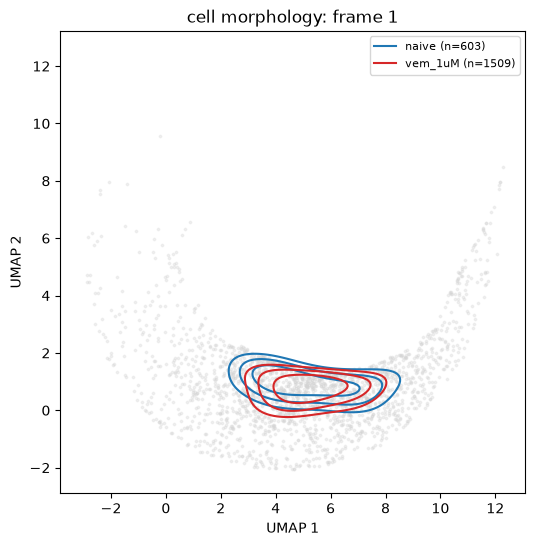

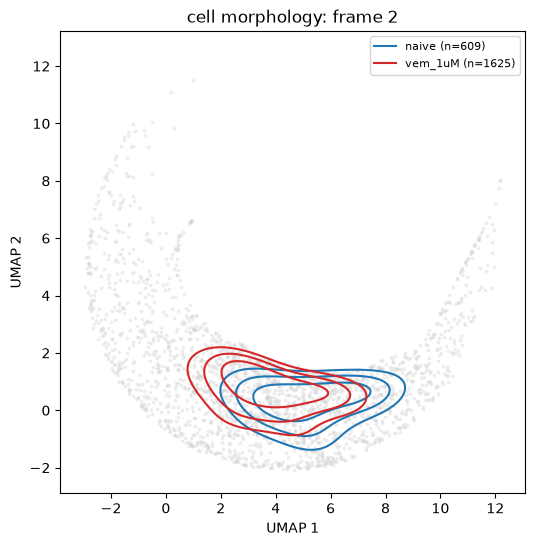

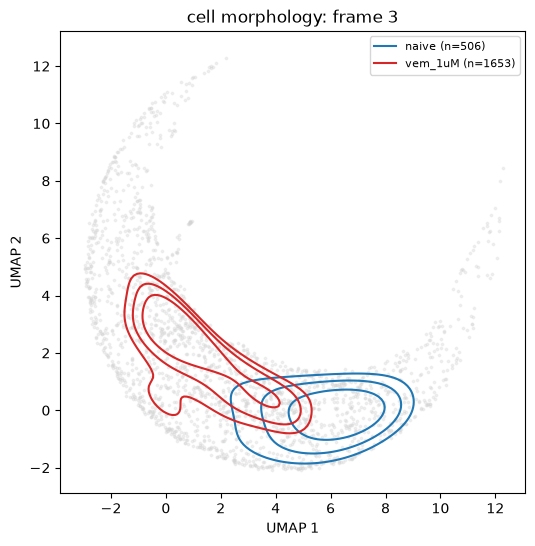

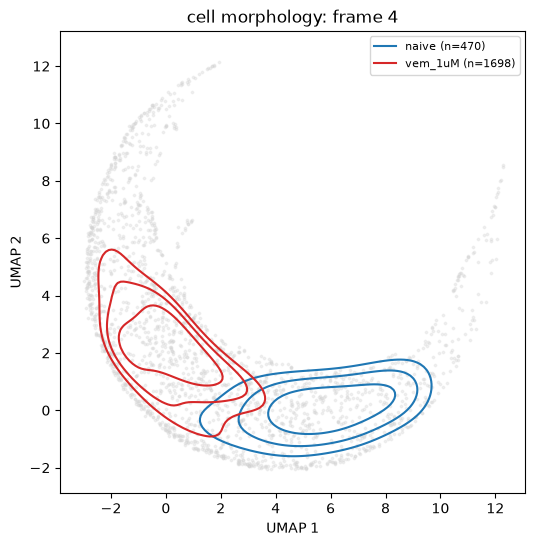

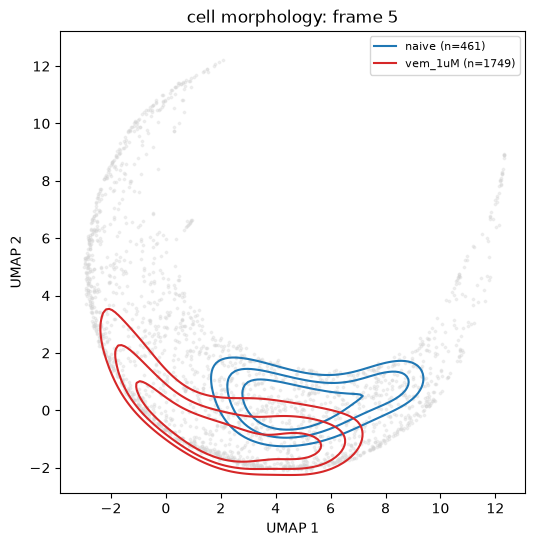

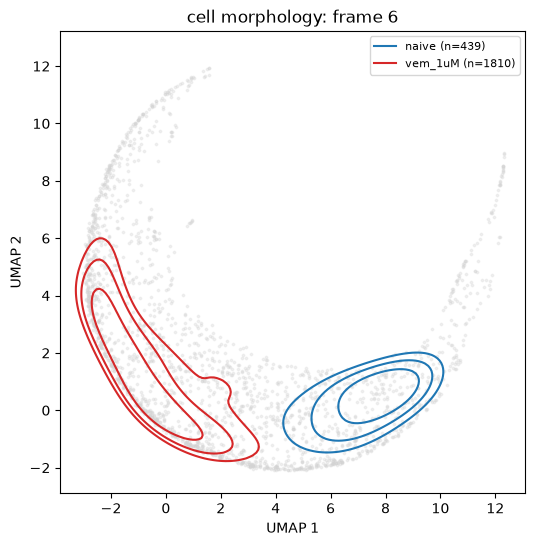

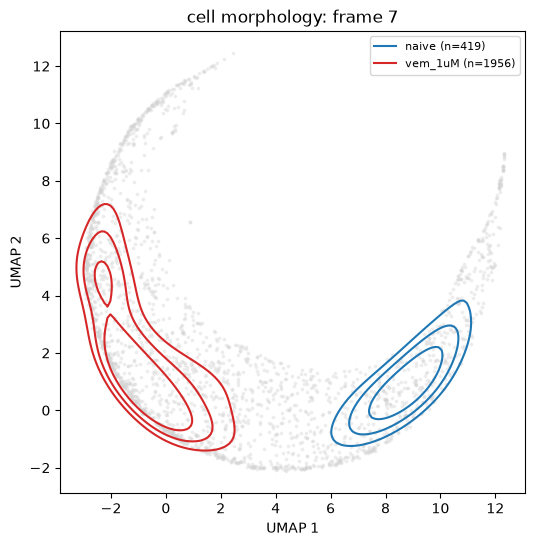

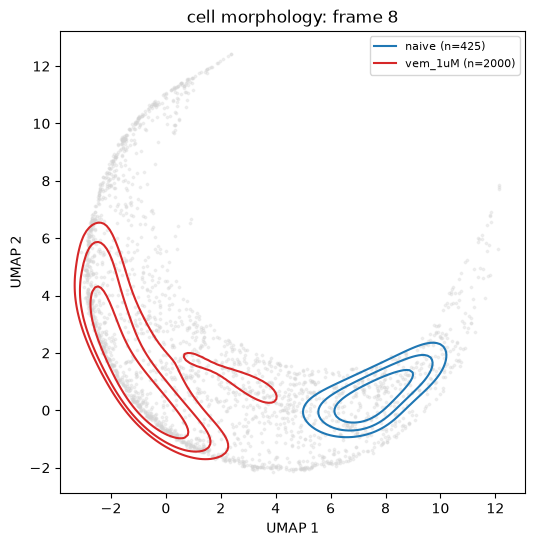

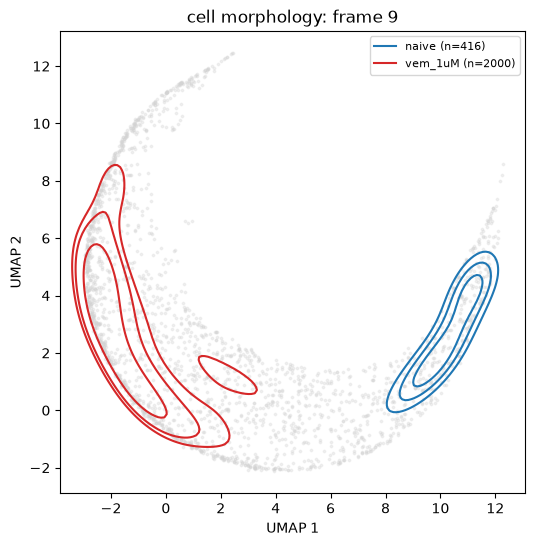

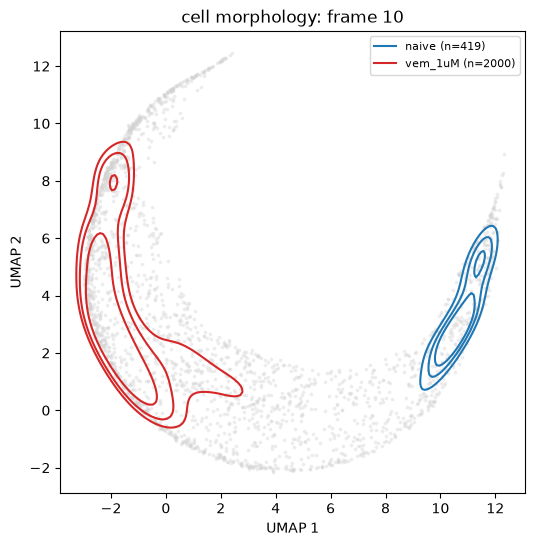

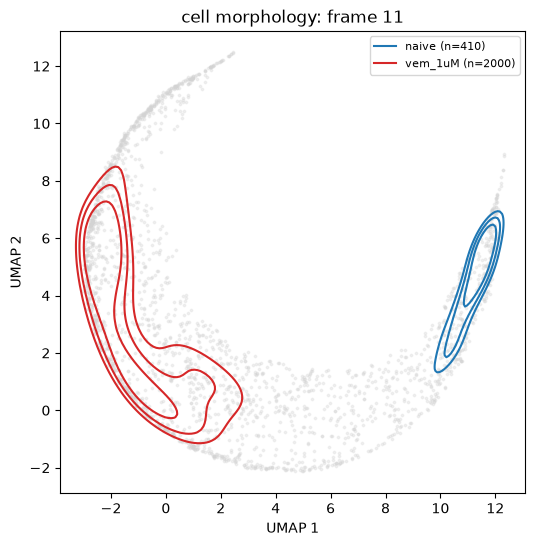

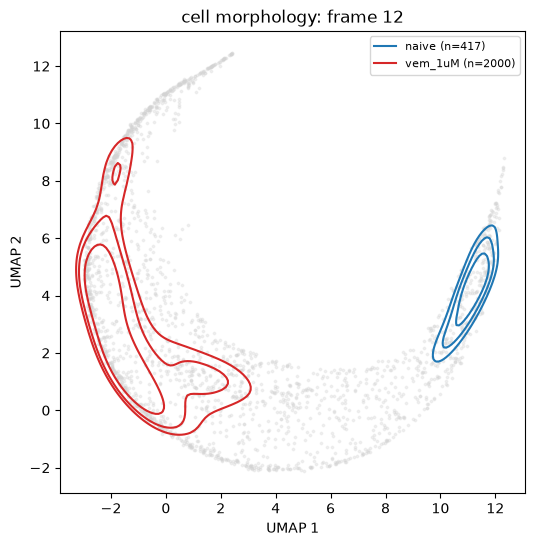

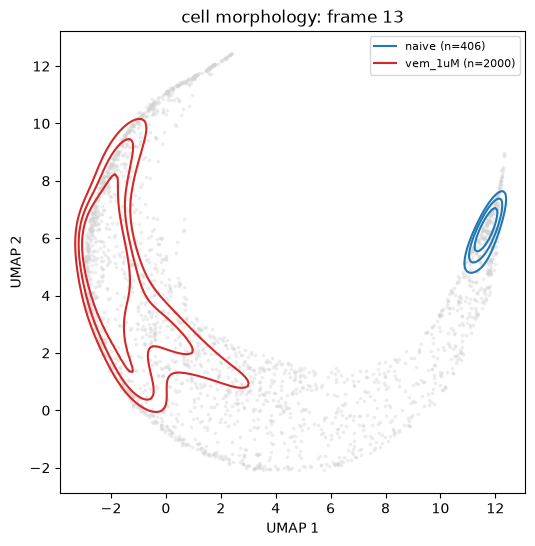

  Saved 13 frame(s) to /gpfs/projects/b1042/GoyalLab/sohini/drug_response_morphology/analyses/01_naive_vs_vem/output/plots/01_umap_by_condition_over_time/cell_umap.pdf and /gpfs/projects/b1042/GoyalLab/sohini/drug_response_morphology/analyses/01_naive_vs_vem/output/plots/01_umap_by_condition_over_time/svgs
[cell/phate] 30000 cells across 13 frames, 2 conditions


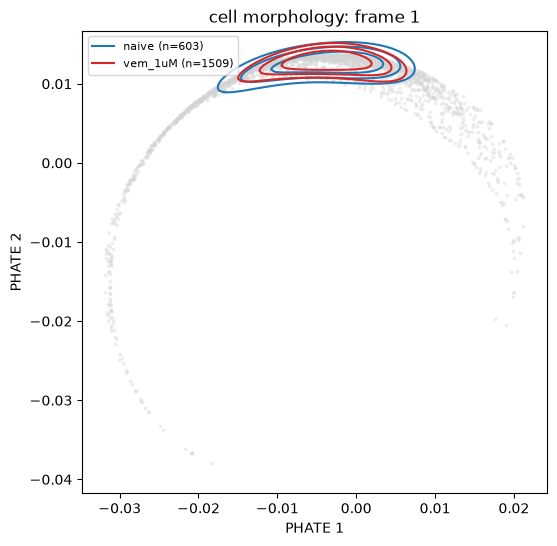

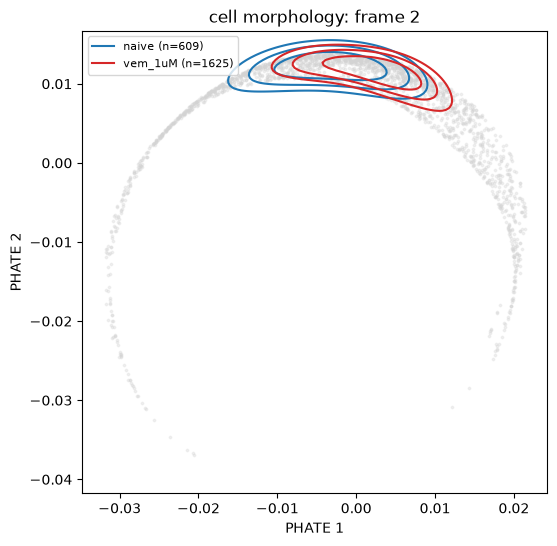

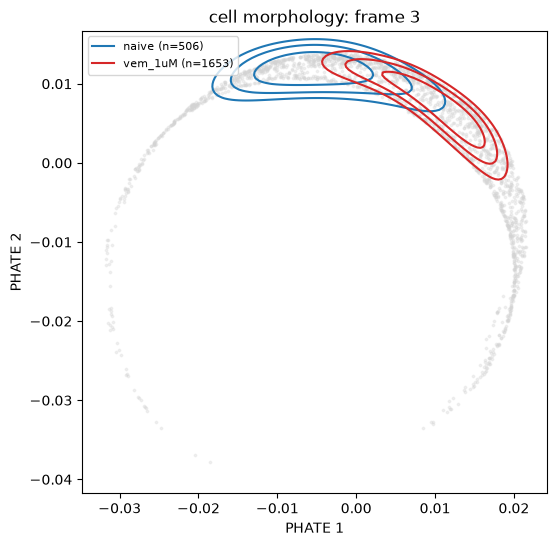

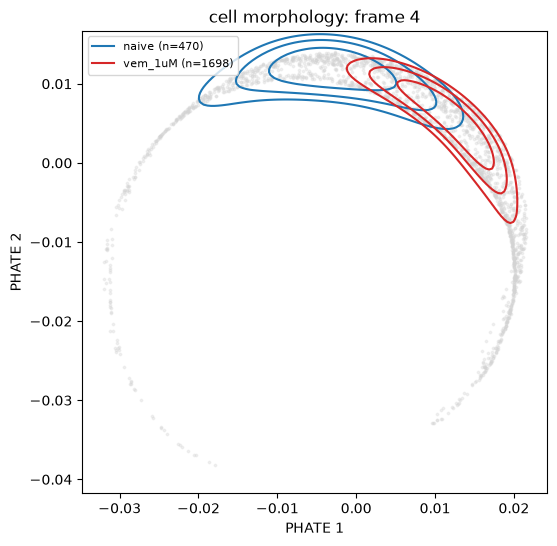

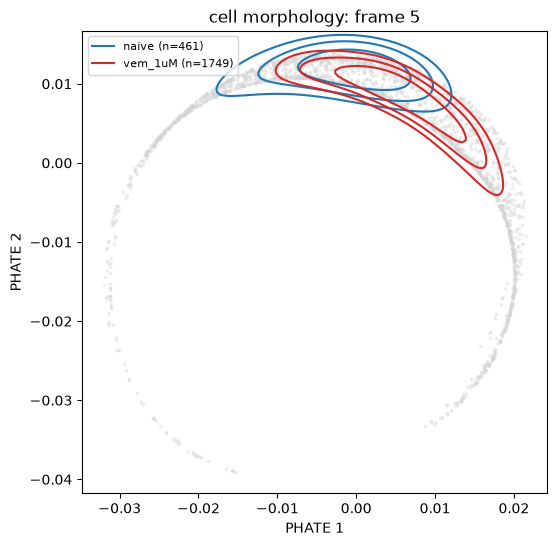

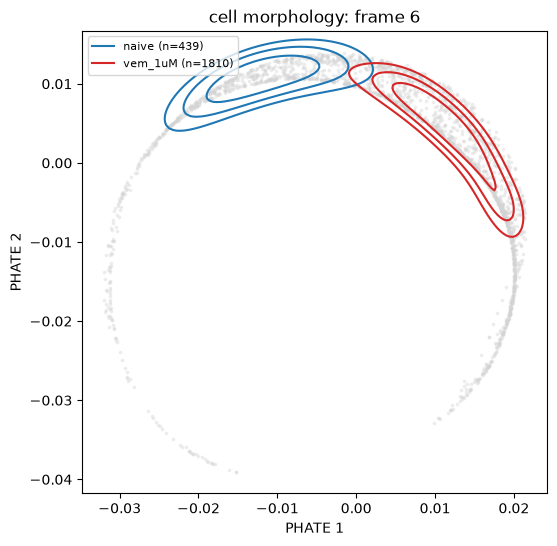

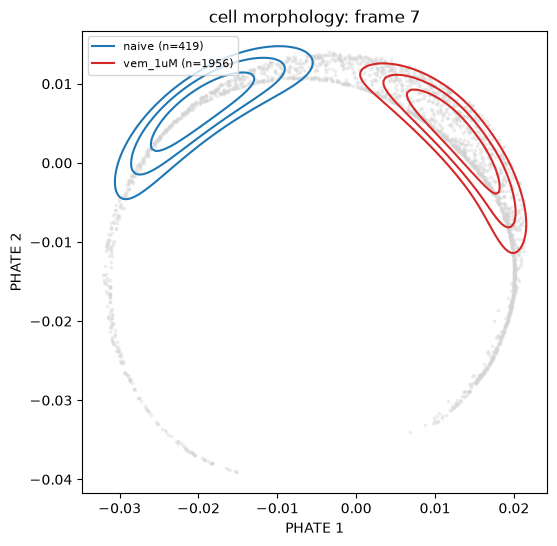

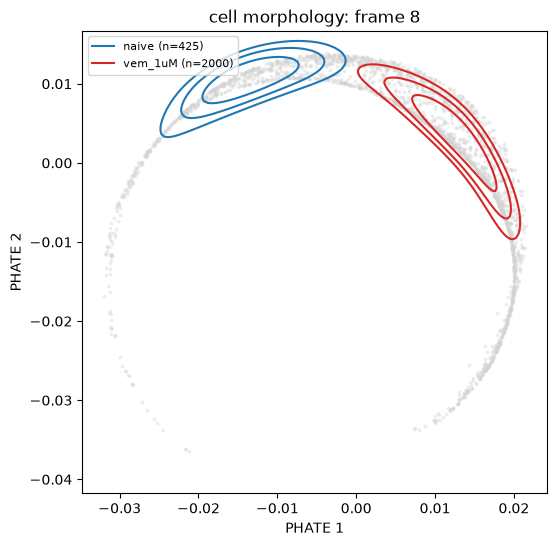

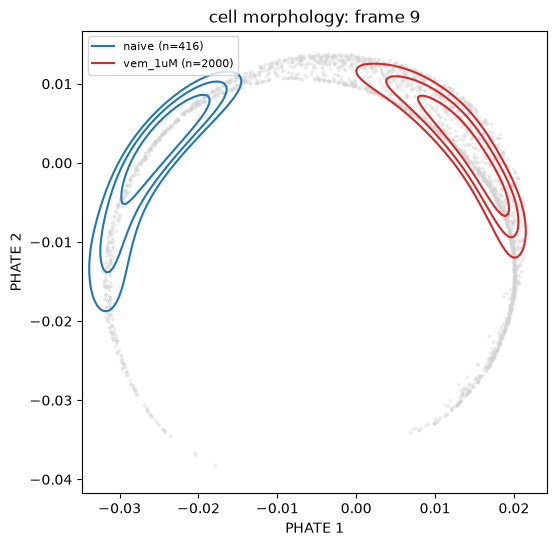

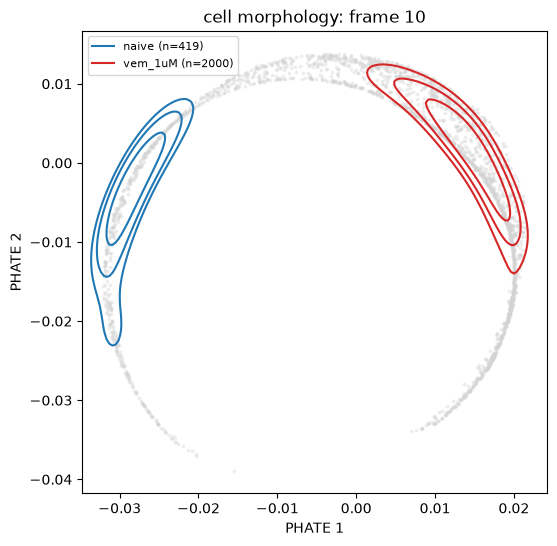

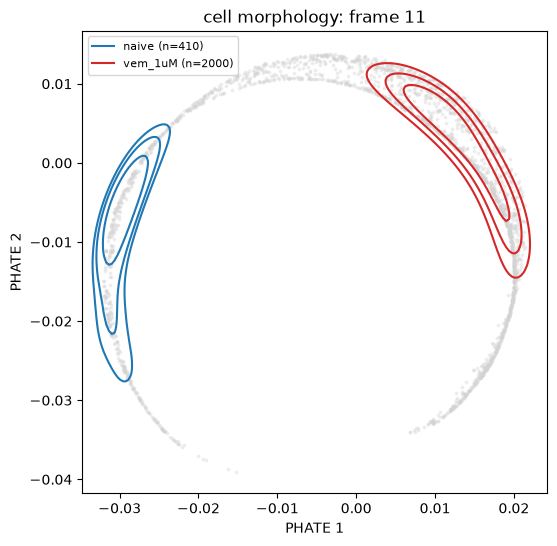

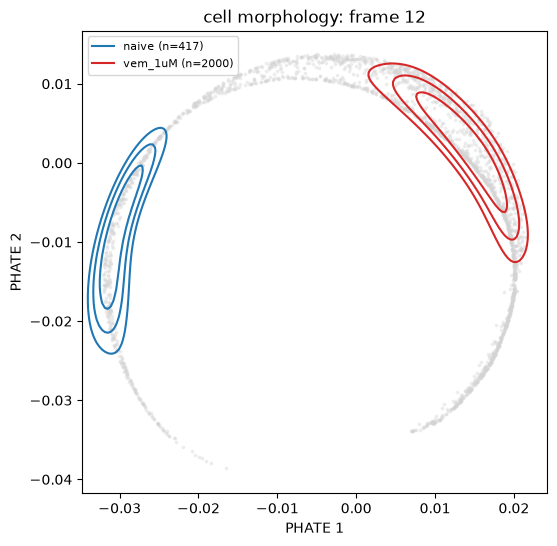

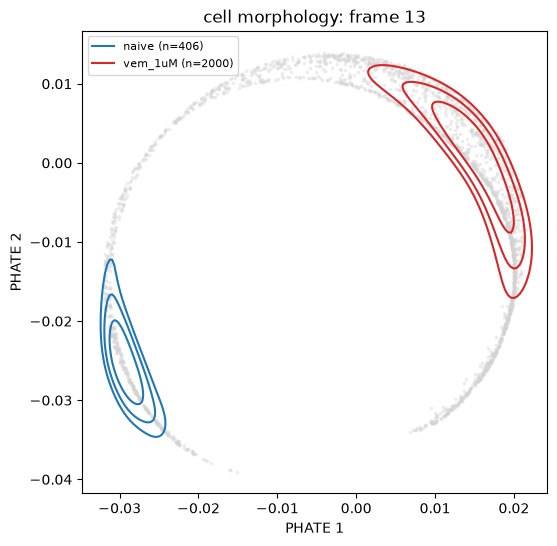

  Saved 13 frame(s) to /gpfs/projects/b1042/GoyalLab/sohini/drug_response_morphology/analyses/01_naive_vs_vem/output/plots/01_umap_by_condition_over_time/cell_phate.pdf and /gpfs/projects/b1042/GoyalLab/sohini/drug_response_morphology/analyses/01_naive_vs_vem/output/plots/01_umap_by_condition_over_time/svgs


In [3]:
cell_dfs = process_modality('cell')


## Run: nuclear morphology

[nuc/umap] 30000 cells across 13 frames, 2 conditions


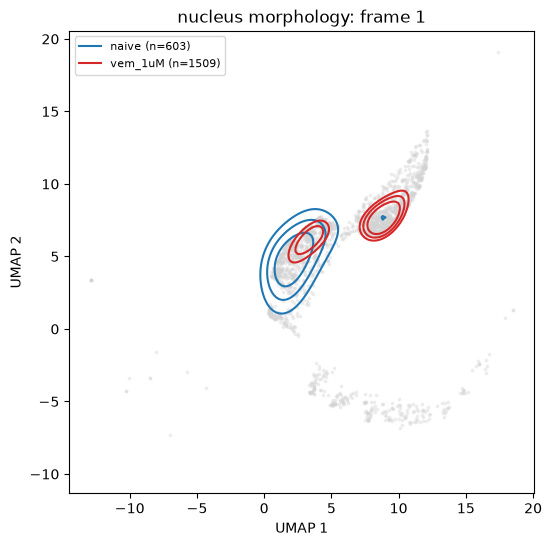

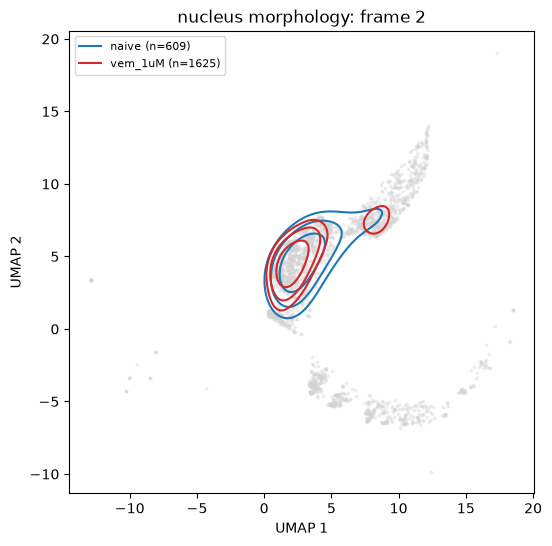

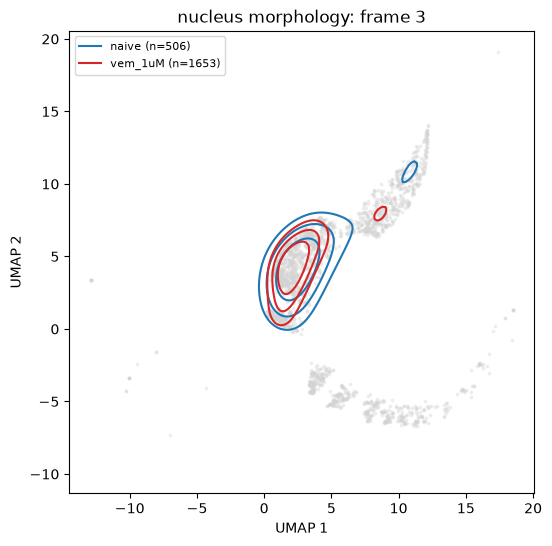

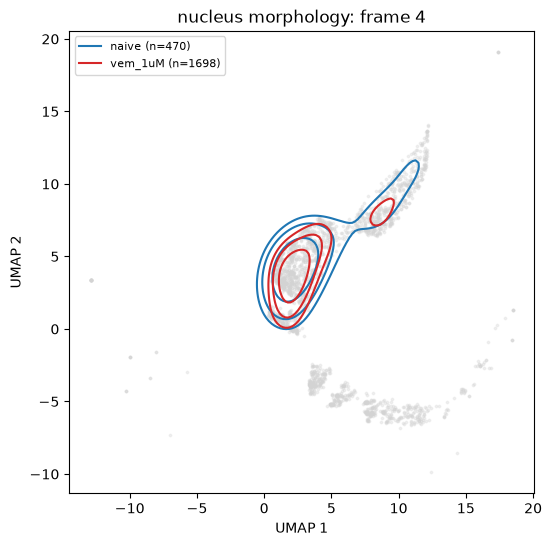

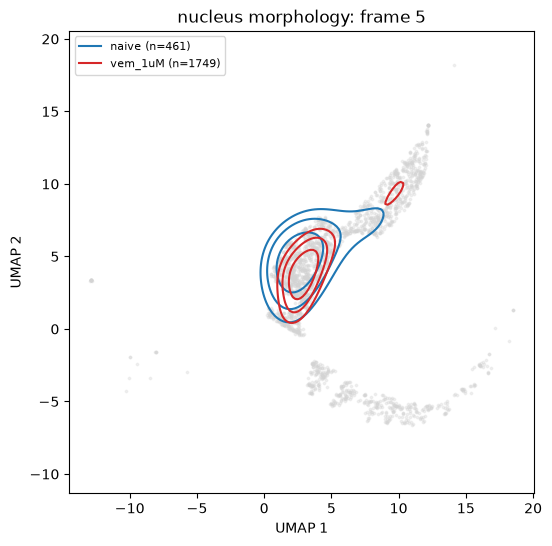

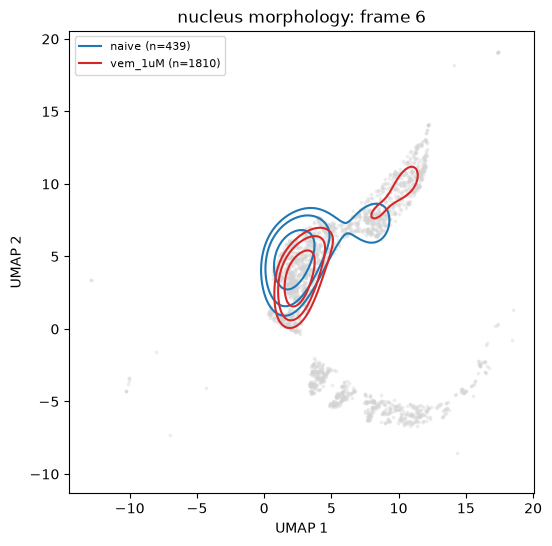

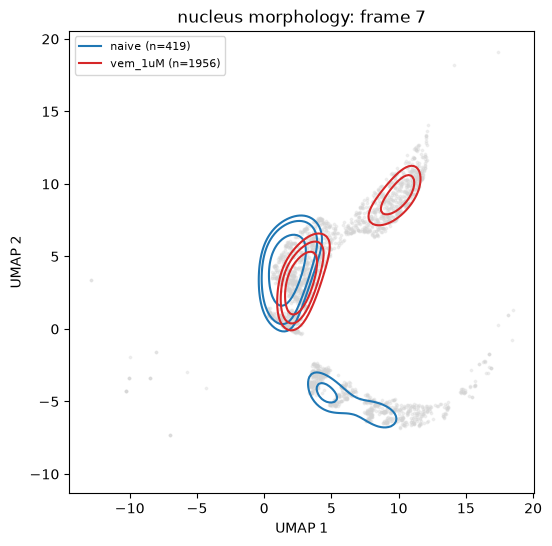

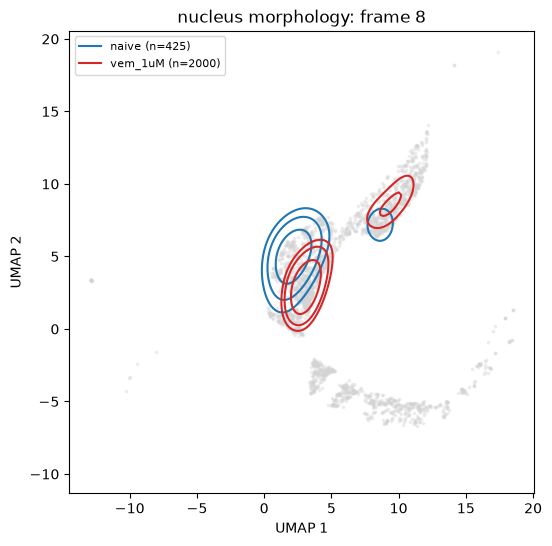

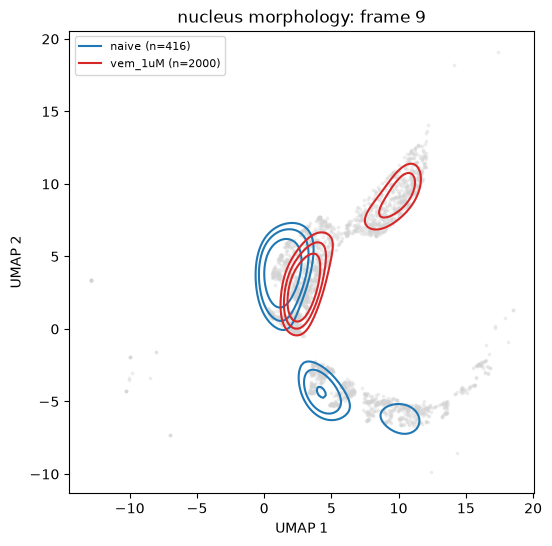

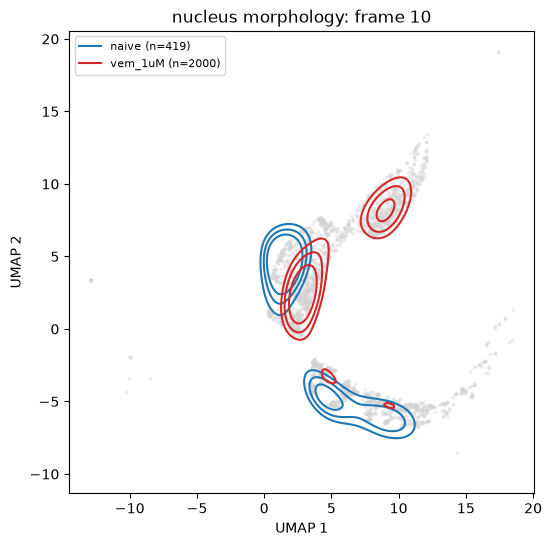

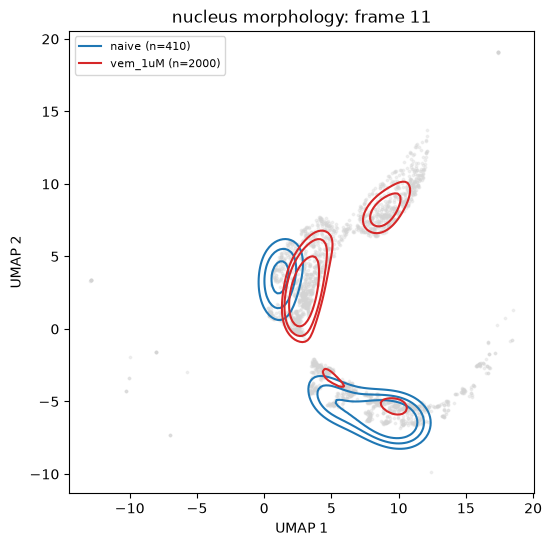

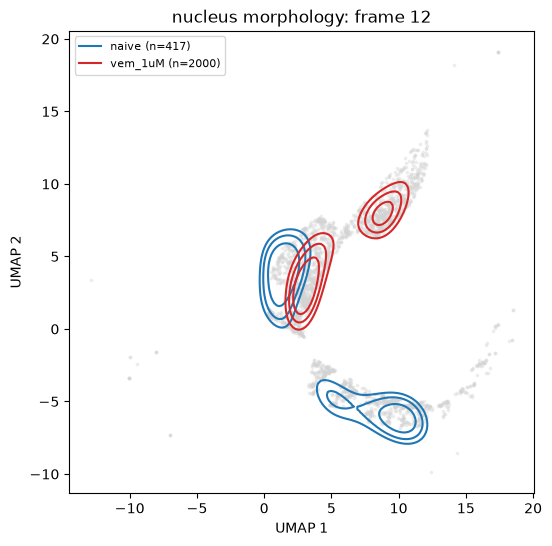

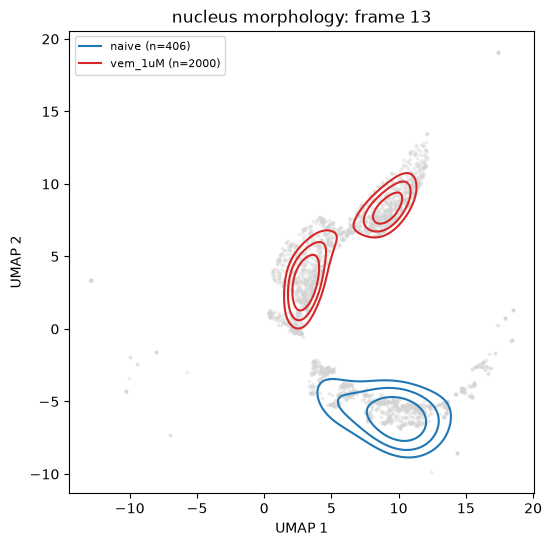

  Saved 13 frame(s) to /gpfs/projects/b1042/GoyalLab/sohini/drug_response_morphology/analyses/01_naive_vs_vem/output/plots/01_umap_by_condition_over_time/nuc_umap.pdf and /gpfs/projects/b1042/GoyalLab/sohini/drug_response_morphology/analyses/01_naive_vs_vem/output/plots/01_umap_by_condition_over_time/svgs
[nuc/phate] 30000 cells across 13 frames, 2 conditions


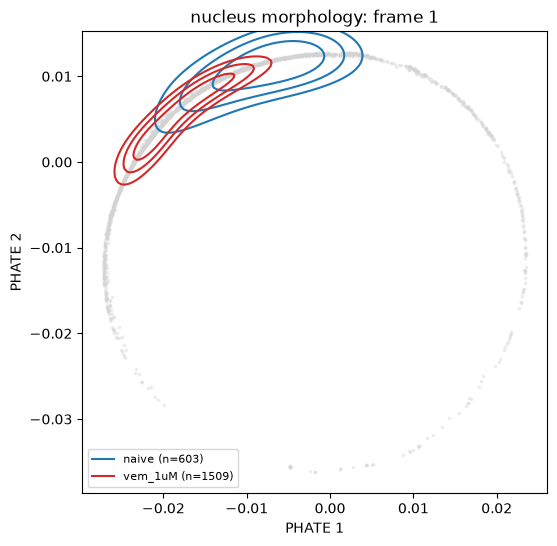

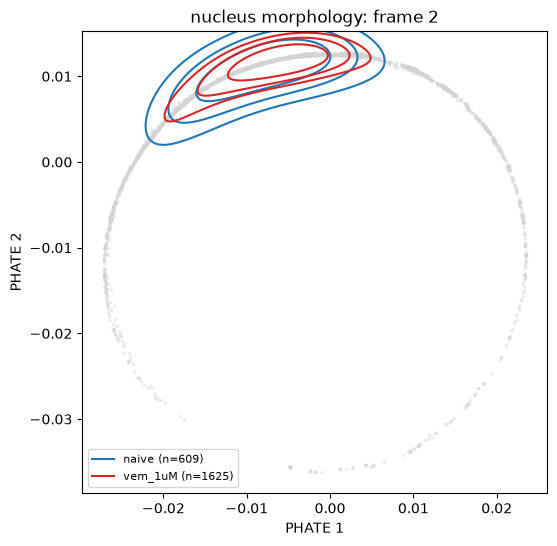

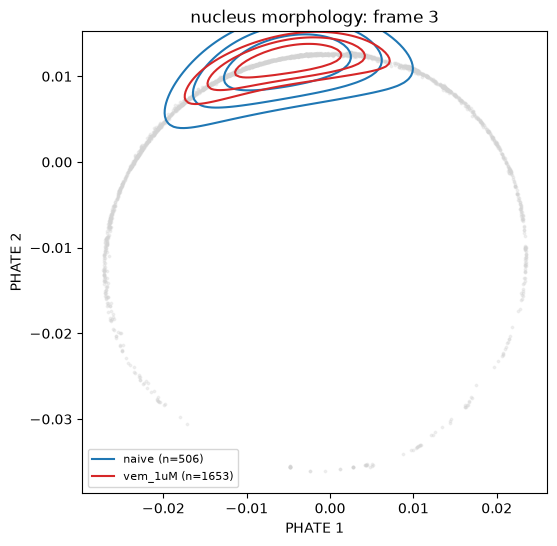

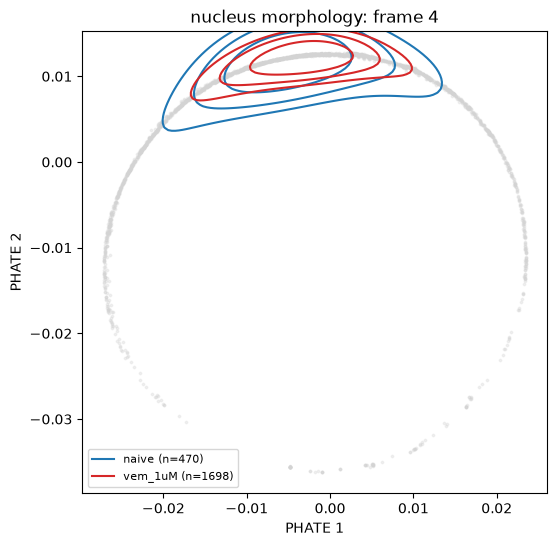

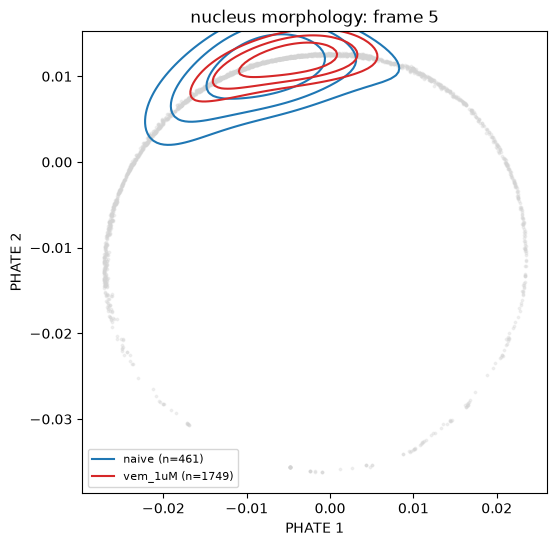

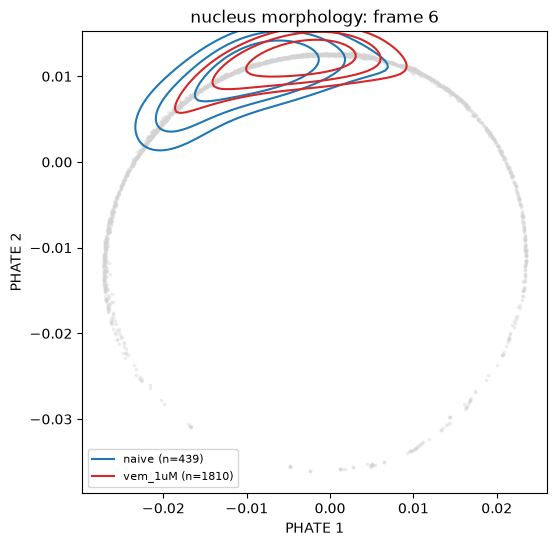

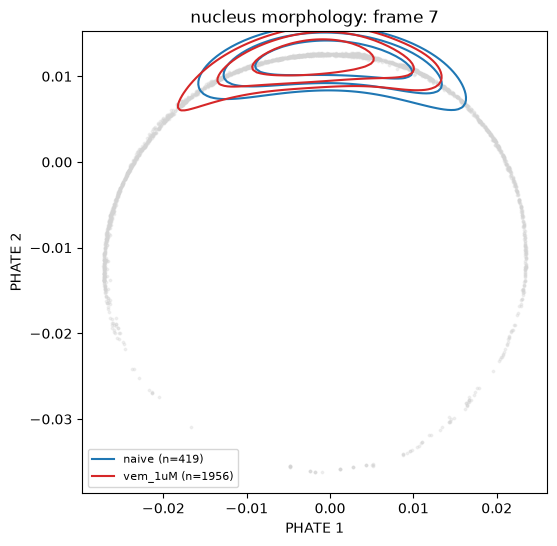

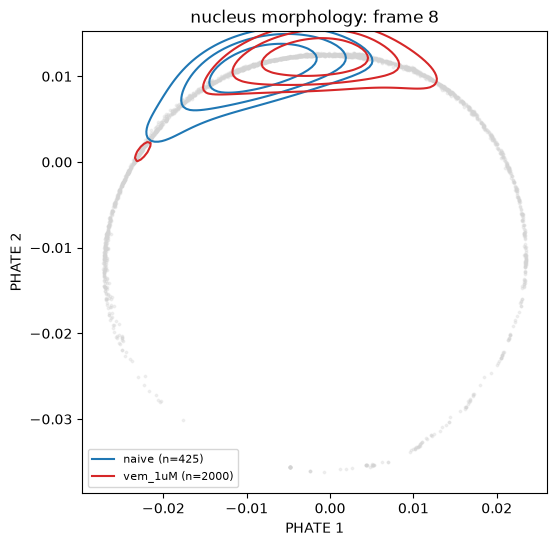

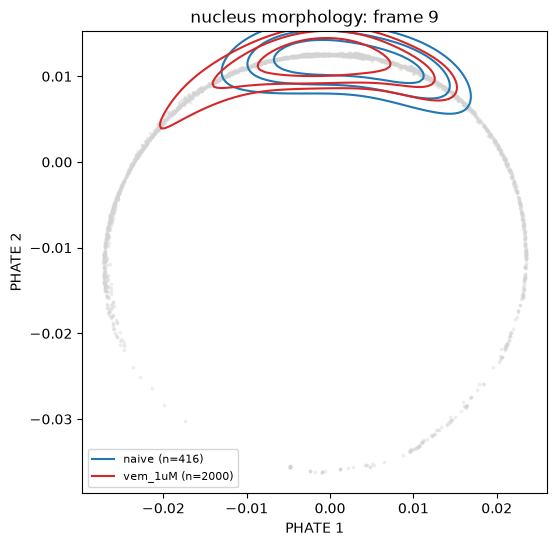

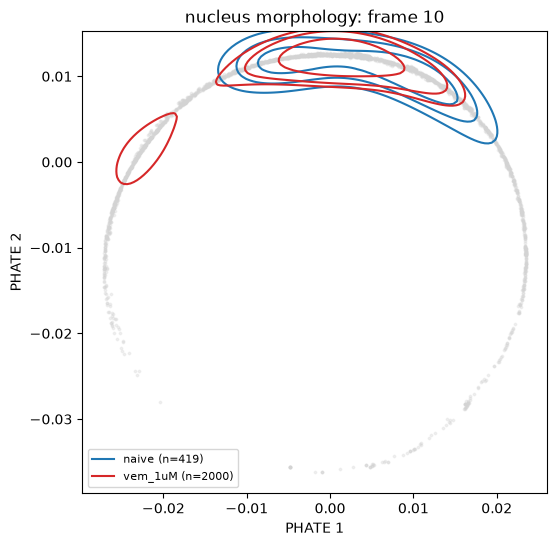

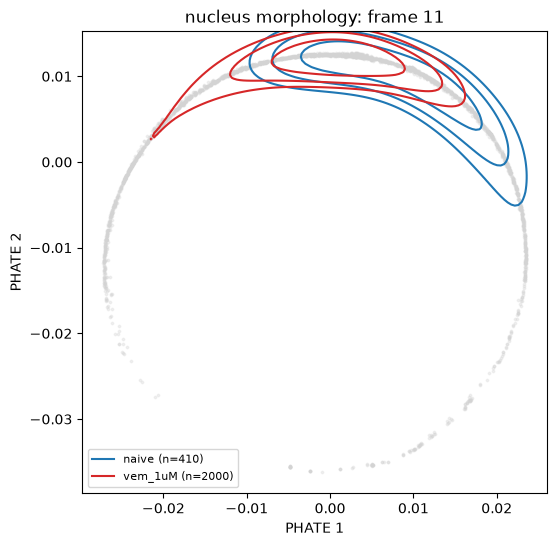

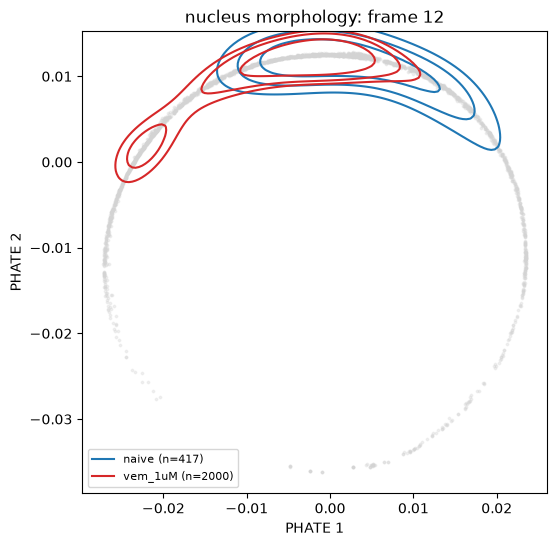

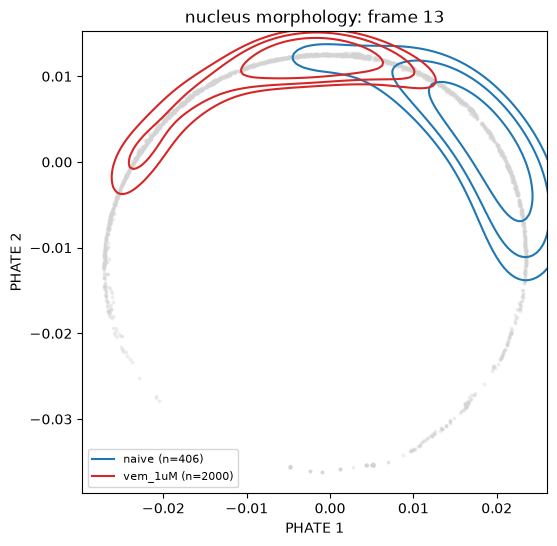

  Saved 13 frame(s) to /gpfs/projects/b1042/GoyalLab/sohini/drug_response_morphology/analyses/01_naive_vs_vem/output/plots/01_umap_by_condition_over_time/nuc_phate.pdf and /gpfs/projects/b1042/GoyalLab/sohini/drug_response_morphology/analyses/01_naive_vs_vem/output/plots/01_umap_by_condition_over_time/svgs


In [4]:
nuc_dfs = process_modality('nuc')
